# The planner's problem under discount-adjusted consumption: TFP shock vs demand shock

`demand_planner.ipynb` finds that the utility-maximising rate sequence sits on a bound of
the grid. `demand_planner_interior.ipynb` traces that to `tprod` putting the nominal
discount factor $\beta^{\tau}$ *inside* a physical quantity and then reading the result as
TFP, and settles on a one-line correction: value consumption physically by dividing the
discount content out at the point where it enters utility,

```python
welfare(y, a_nat)        ->        welfare(y - d, a_nat - d),      d = log(Atilde / Z)
```

A discount factor cannot sit inside a concave period utility — $u(\beta^\tau z) \neq
\beta^\tau u(z)$ — and the $\beta^t$ in the welfare sum already prices delay, so leaving
$\beta^\tau$ in the quantity double-counts it. Consumption becomes $C_t = e^{y_t-d_t}$
while labour $N_t = e^{y_t-a_t}$ is untouched, and the IS block is left exactly as it was,
so the natural level of output keeps its financing wedge.

This notebook takes that criterion as given and asks what the **planner's problem actually
looks like** under it, for both shocks:

* a $3\%$ TFP shock propagating through the staggered time-to-produce structure;
* a $1\%$ demand shock.

Headline findings, all established below:

| | TFP shock | demand shock |
|---|---|---|
| utility along a uniform rate | interior, peaks at $\rho$ | interior, peaks at $\rho$ |
| is the first best attainable? | yes | yes |
| free periods needed | $L = 11$ | $L = 4$ |
| optimal rate path | **oscillates**, robustly | smooth |
| optimum unique? | effectively yes | no — a flat set |
| time-to-build changes welfare? | no, only the required path | no, only the required path |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration

Identical to the other `semi_endo` notebooks.

In [2]:
sigma = 5
beta = 1 / (1.0 + 0.01)
beta1 = 1 / (1.0 + 0.01 * np.exp(30 / (36.5 * 0.9)))
beta_hh = beta
rho = 1 / beta_hh - 1

gamma = 2.0
eta = 2.0
PHI_YA = (1 + eta) / (gamma + eta)
chi = 1.0                      # subsidy offsets the markup: steady state is efficient

A_SHOCK = 0.97                 # 3 per cent TFP decline
D_SHOCK = 0.01                 # 1 per cent demand shock
T = 30

print(f'gamma={gamma}, eta={eta}, phi_ya={PHI_YA:.4f}, rho={rho:.6f}')
print(f'A shock = {A_SHOCK} ({100*(1-A_SHOCK):.0f}%),  demand shock = {100*D_SHOCK:.0f}%')

gamma=2.0, eta=2.0, phi_ya=0.7500, rho=0.010000
A shock = 0.97 (3%),  demand shock = 1%


In [3]:
data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * 36.5 / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N)
pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

tvals = tau.astype(int).to_numpy()
N_array = np.array(N)
NFIRMS = len(tvals)
Z_PHYS = c * (tvals + N_array)          # physical output per firm, no discount factor
print(f'c = {c:.7f}   mean tau = {tau.mean():.4f}   firms = {NFIRMS}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_32214/3817739888.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


c = 0.9018018   mean tau = 2.8885   firms = 269


In [4]:
def generate_pattern_array_with_extra_rows(tau, shock=A_SHOCK):
    """Staggering matrix: which firms have re-optimised by period t."""
    tau = np.asarray(tau)
    n = len(tau) + int(np.min(tau))
    m = int(np.max(tau)) + int(np.min(tau))
    missing = len(set(range(int(max(tau)) + 1)) - set(tau))
    A = np.ones((m + 2, n + missing), dtype=float)
    count = 0
    for i in range(1, m + 2):
        firms = tau[tau == i - 1]
        for j in range(len(firms)):
            A[i, n - i - j - count] = shock
        if len(firms) > 1:
            count += len(firms) - 1
    return np.vstack([A, np.ones(n + missing)])[:, 0:n - int(np.min(tau))]


A_PATTERN = generate_pattern_array_with_extra_rows(tau)
print('staggering matrix:', A_PATTERN.shape,
      f'-> shock fully worked through by t = {A_PATTERN.shape[0] - 1}')

staggering matrix: (16, 269) -> shock fully worked through by t = 15


## 2. The model, with the adjustment

`solve` is `demand_planner.ipynb`'s pipeline verbatim, plus two derived series:
$d_t = \log(\tilde A_t/Z_t)$, the discount content of measured TFP, and the physical
counterparts $y^{\text{phys}} = y - d$, $a^{\text{phys}} = a - d$. Welfare is evaluated on
those. The efficient benchmark $y^e = \varphi_{ya}a^{\text{phys}}$ depends only on physical
productivity, so it is policy-free.

In [5]:
def shock_matrix(T, on):
    ps = np.ones((T, NFIRMS))
    if on:
        ps[0:15] = A_PATTERN[1:]
    return ps


def disc_matrix(r, T, time_to_build=True):
    """Cumulative beta^tau_i by period, implied by rate path r over its first len(r) periods."""
    L = len(r)
    irl = np.ones((T, T)) * rho
    blk = np.full((L, L), rho, dtype=float)
    for i in range(L):
        blk[i, :i + 1] = np.asarray(r, float)[i::-1]
    irl[0:L, :L] = blk
    ce = np.ones((T, T + 1))
    ce[:, 1:] = np.cumprod(1.0 / (1.0 + irl), axis=1)
    tv = tvals if time_to_build else np.zeros_like(tvals)
    return ce[:, tv]


def solve(r, T=T, a_shock=False, demand=None, time_to_build=True):
    """demand_planner.ipynb's pipeline + the discount adjustment."""
    sm = shock_matrix(T, a_shock)
    disc = disc_matrix(r, T, time_to_build)
    tprod = disc * Z_PHYS * sm

    A_price = np.sum(1 / tprod**(sigma - 1), axis=1)**(1 / (sigma - 1))
    A_til = np.sum(tprod**(sigma - 1), axis=1)**(1 / (sigma - 1))     # measured (cost) TFP
    Z_t = np.sum((Z_PHYS * sm)**(sigma - 1), axis=1)**(1 / (sigma - 1))   # physical

    ip = np.ones(T) * rho; ip[:len(r)] = r
    dem = np.zeros(T) if demand is None else np.asarray(demand, float)
    a_nat = np.log(A_til) - np.log(A_til)[-1]
    d = np.log(A_til) - np.log(Z_t); d = d - d[-1]                     # discount content

    price_level = np.log(A_price)
    pi = np.zeros(T); pi[1:] = price_level[1:] - price_level[:-1]
    pi_fwd = np.r_[pi[1:], 0.0]
    y_nat = PHI_YA * a_nat
    dy = np.r_[y_nat[1:] - y_nat[:-1], 0.0]
    r_nat = rho - dem + gamma * dy

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (ip[t] - pi_fwd[t] - r_nat[t])
    x = x[:T]
    y = x + y_nat

    a_phys = a_nat - d
    return dict(y=y, a_nat=a_nat, d=d, x=x, i=ip, pi=pi, y_nat=y_nat, r_nat=r_nat,
                y_phys=y - d, a_phys=a_phys, y_eff=PHI_YA * a_phys)


def welfare(s):
    """Discounted utility on the PHYSICAL paths.  Returns (U, U_cons, U_labour)."""
    y, a = s['y_phys'], s['a_phys']
    disc = beta_hh ** np.arange(len(y))
    C = np.exp(y)
    Nl = np.exp(y - a)
    uc = C**(1 - gamma) / (1 - gamma)
    un = chi * Nl**(1 + eta) / (1 + eta)
    return float(np.sum(disc * (uc - un))), float(np.sum(disc * uc)), float(np.sum(disc * un))


def welfare_unadjusted(s):
    """The original criterion, for contrast: C = e^y with the discount still inside."""
    y, a = s['y'], s['a_nat']
    disc = beta_hh ** np.arange(len(y))
    C = np.exp(y); Nl = np.exp(y - a)
    return float(np.sum(disc * (C**(1-gamma)/(1-gamma) - chi * Nl**(1+eta)/(1+eta))))


def cons_equivalent(U_alt, UC_base, UN_base):
    return ((U_alt + UN_base) / UC_base)**(1.0 / (1.0 - gamma)) - 1.0


CASES = {'TFP shock (3%)':   dict(a_shock=True,  demand=None),
         'Demand shock (1%)': dict(a_shock=False,
                                   demand=np.r_[D_SHOCK, np.zeros(T - 1)])}
print('cases:', list(CASES))

cases: ['TFP shock (3%)', 'Demand shock (1%)']


## 3. Is the problem interior for both shocks?

Sweep a uniform rate held for eight periods. This is the diagnostic that fails in the
original notebook: unadjusted utility is monotone in $i$, so the optimiser runs to the
bound.

In [6]:
grid = np.array([0.0, 0.0025, 0.005, 0.0075, rho, 0.0125, 0.015, 0.02])
sweep = {}
for name, kw in CASES.items():
    ua = np.array([welfare(solve(np.ones(8) * lv, **kw))[0] for lv in grid])
    uu = np.array([welfare_unadjusted(solve(np.ones(8) * lv, **kw)) for lv in grid])
    sweep[name] = (ua, uu)
    ia, iu = int(np.argmax(ua)), int(np.argmax(uu))
    print(f'\n{name}')
    print(f'{"uniform i":>10} {"U adjusted":>18} {"":<8} {"U unadjusted":>18} {"":<8}')
    print('-' * 76)
    for k, lv in enumerate(grid):
        # mark each column separately -- a single trailing marker reads as if it
        # applied to both, which it does not: the two columns peak in different places
        print(f'{lv:>10.4f} {ua[k]:>18.9f} {"<- max" if k == ia else "":<8} '
              f'{uu[k]:>18.9f} {"<- max" if k == iu else "":<8}')
    print(f'   adjusted  : argmax at i = {grid[int(np.argmax(ua))]:.4f}, '
          f'interior = {int(np.argmax(ua)) not in (0, len(grid) - 1)}')
    print(f'   unadjusted: argmax at i = {grid[int(np.argmax(uu))]:.4f}, '
          f'monotone in i = {bool(np.all(np.diff(uu) < 0))}')


TFP shock (3%)
 uniform i         U adjusted                U unadjusted         
----------------------------------------------------------------------------
    0.0000      -34.787920516               -34.607236006 <- max  
    0.0025      -34.785646349               -34.649899964         
    0.0050      -34.784011272               -34.693347569         
    0.0075      -34.783008752               -34.737580529         
    0.0100      -34.782632633 <- max        -34.782600870         
    0.0125      -34.782877127               -34.828410929         
    0.0150      -34.783736801               -34.875013350         
    0.0200      -34.787281681               -34.970607339         
   adjusted  : argmax at i = 0.0100, interior = True
   unadjusted: argmax at i = 0.0000, monotone in i = True

Demand shock (1%)
 uniform i         U adjusted                U unadjusted         
----------------------------------------------------------------------------
    0.0000      -34.758714072 

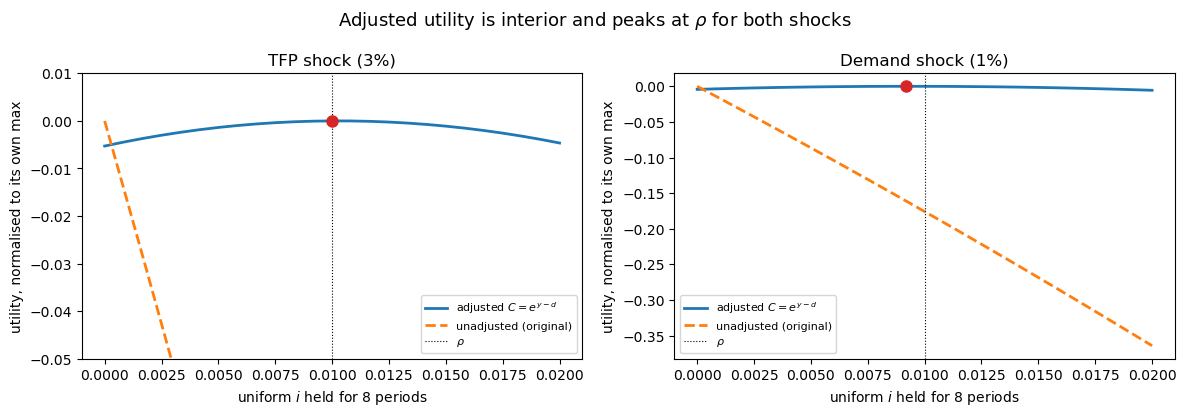

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
ii = np.linspace(0.0, 0.02, 25)
for ax, (name, kw) in zip(axes, CASES.items()):
    ua = np.array([welfare(solve(np.ones(8) * lv, **kw))[0] for lv in ii])
    uu = np.array([welfare_unadjusted(solve(np.ones(8) * lv, **kw)) for lv in ii])
    ax.plot(ii, ua - ua.max(), lw=2, label='adjusted $C=e^{y-d}$')
    ax.plot(ii, uu - uu.max(), lw=2, ls='--', label='unadjusted (original)')
    ax.axvline(rho, color='k', lw=0.8, ls=':', label=r'$\rho$')
    ax.plot(ii[int(np.argmax(ua))], 0.0, 'o', ms=8, color='C3')
    ax.set_xlabel('uniform $i$ held for 8 periods')
    ax.set_ylabel('utility, normalised to its own max')
    ax.set_title(name); ax.legend(fontsize=8)
axes[0].set_ylim(-0.05, 0.01)
fig.suptitle('Adjusted utility is interior and peaks at $\\rho$ for both shocks', fontsize=13)
plt.tight_layout()
plt.savefig('../semi_endo_planner_adj_interior.png', dpi=150, bbox_inches='tight')
plt.show()

Both shocks now give a well-behaved interior problem peaking at $\rho$. The unadjusted
curves are monotone and would send any optimiser to the lower bound.

## 4. Solving the planner's problem

Two things force a different solver routine from the one in `demand_planner.ipynb`.

1. The optimum can be **non-unique** — for the demand shock several rate paths give
   identical utility — so the "has the last free period returned to $\rho$?" escalation
   test never fires. Convergence has to be judged on the *objective*.
2. The landscape is flat near the optimum, so L-BFGS-B occasionally stops a hair short.
   Each $L$ is therefore solved from several starting points and the best kept.

In [8]:
SEEDS = [lambda L: np.ones(L) * rho,
         lambda L: np.linspace(0.005, 0.015, L),
         lambda L: np.full(L, 0.005)]


def escalate(kw, L_range=range(3, 17), bounds=(0.0, 0.05), tol=1e-9, verbose=True):
    """Grow the free-policy horizon L; judge convergence on the OBJECTIVE, not the tail."""
    def obj(r):
        return -welfare(solve(r, **kw))[0]

    hist = {}
    if verbose:
        print(f'{"L":>3} {"objective":>20} {"peak |y-y_eff|":>16} {"last i":>9}   sequence')
        print('-' * 96)
    for L in L_range:
        best = None
        for seed in SEEDS:
            res = minimize(obj, seed(L), method='L-BFGS-B', bounds=[bounds] * L,
                           options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
            if best is None or res.fun < best.fun:
                best = res
        s = solve(best.x, **kw)
        hist[L] = (best.x.copy(), float(best.fun), s)
        if verbose:
            print(f'{L:>3} {best.fun:>20.12f} '
                  f'{np.max(np.abs(s["y_phys"] - s["y_eff"])):>16.3e} {best.x[-1]:>9.5f}   '
                  f'{np.round(best.x[:6], 5)}{" ..." if L > 6 else ""}')
    bestval = min(v[1] for v in hist.values())
    L_conv = min(L for L, v in hist.items() if v[1] - bestval < tol)
    if verbose:
        print(f'\n-> best objective {bestval:.12f}, first reached at L = {L_conv}')
    return hist, L_conv


results = {}
for name, kw in CASES.items():
    print('=' * 96); print(name); print('=' * 96)
    results[name] = escalate(kw)
    print()

TFP shock (3%)
  L            objective   peak |y-y_eff|    last i   sequence
------------------------------------------------------------------------------------------------


  3      34.782623139637        1.755e-03   0.01962   [0.02076 0.      0.01962]


  4      34.782620912918        1.755e-03   0.01355   [0.01171 0.00812 0.00822 0.01355]


  5      34.782614959712        3.992e-04   0.01772   [0.02099 0.      0.01941 0.00259 0.01772]


  6      34.782614655529        1.098e-04   0.01361   [0.0148  0.00541 0.01192 0.00992 0.00899 0.01361]


...

 12      34.754380404668        2.068e-07   0.00889   [0.00118 0.00778 0.00881 0.00798 0.00914 0.00872] ...


 13      34.754380404668        2.196e-07   0.00913   [0.00055 0.00834 0.00808 0.00867 0.00829 0.00961] ...


 14      34.754380404668        3.352e-07   0.00936   [0.00098 0.00795 0.00858 0.00819 0.00888 0.009  ] ...


 15      34.754380404668        3.925e-07   0.00951   [0.00069 0.00822 0.00824 0.00851 0.00848 0.00941] ...


 16      34.754380404668        3.386e-07   0.00963   [0.00089 0.00804 0.00848 0.00829 0.00875 0.00913] ...

-> best objective 34.754380404667, first reached at L = 4



The contrast is the main result of the notebook.

* The **demand shock** converges at $L=4$ and the planner drives the physical output gap to
  $\sim\!3\times10^{-7}$ — the first best is attained with four free periods.
* The **TFP shock** needs $L=11$ for the objective to converge, and $L=12$ before the gap
  itself collapses to $\sim\!3\times10^{-7}$. That is not a numerical accident: the
  staggering matrix takes 15 periods to work through, so policy needs comparable freedom
  before it can neutralise the whole path. The gap is still $1.8\times10^{-3}$ at $L=3$ —
  about the size of the shock's own effect on potential — and $10^{-4}$ as late as $L=10$.

In [9]:
w = 44
summary = {}
for name, kw in CASES.items():
    hist, L_conv = results[name]
    r_opt, f_opt, s_opt = hist[L_conv]
    s_base = solve(np.ones(3) * rho, **kw)
    U_b, UC_b, UN_b = welfare(s_base)
    U_o = welfare(s_opt)[0]
    summary[name] = (r_opt, s_opt, s_base)
    print('=' * 78); print(name); print('=' * 78)
    print(f'{"free periods needed (objective converged)":<{w}}: {L_conv}')
    print(f'{"utility, no policy change":<{w}}: {U_b:.10f}')
    print(f'{"utility, planner":<{w}}: {U_o:.10f}')
    print(f'{"welfare gain (consumption equivalent)":<{w}}: '
          f'{100 * cons_equivalent(U_o, UC_b, UN_b):+.6f}% of ss C')
    print(f'{"peak |y-y_eff|, no policy change":<{w}}: '
          f'{np.max(np.abs(s_base["y_phys"] - s_base["y_eff"])):.4e}')
    print(f'{"peak |y-y_eff|, planner":<{w}}: '
          f'{np.max(np.abs(s_opt["y_phys"] - s_opt["y_eff"])):.4e}')
    print(f'{"optimum on a bound of [0, 0.05]":<{w}}: '
          f'{bool(np.any(np.isclose(r_opt, 0.0) | np.isclose(r_opt, 0.05)))}')
    print(f'{"optimal rate path":<{w}}: {np.round(r_opt[:8], 5)}')
    print(f'{"physical TFP trough a_phys":<{w}}: {s_opt["a_phys"].min():.6f}')
    print()

TFP shock (3%)
free periods needed (objective converged)   : 11
utility, no policy change                   : -34.7826326331
utility, planner                            : -34.7826146090
welfare gain (consumption equivalent)       : +0.000069% of ss C
peak |y-y_eff|, no policy change            : 2.1894e-03
peak |y-y_eff|, planner                     : 9.6327e-06
optimum on a bound of [0, 0.05]             : False
optimal rate path                           : [0.01687 0.00359 0.01442 0.00748 0.01188 0.01059 0.01067 0.00982]
physical TFP trough a_phys                  : -0.010803

Demand shock (1%)
free periods needed (objective converged)   : 4
utility, no policy change                   : -34.7544302387
utility, planner                            : -34.7543804047
welfare gain (consumption equivalent)       : +0.000191% of ss C
peak |y-y_eff|, no policy change            : 5.0000e-03
peak |y-y_eff|, planner                     : 2.1697e-07
optimum on a bound of [0, 0.05]             : F

## 5. Impulse responses

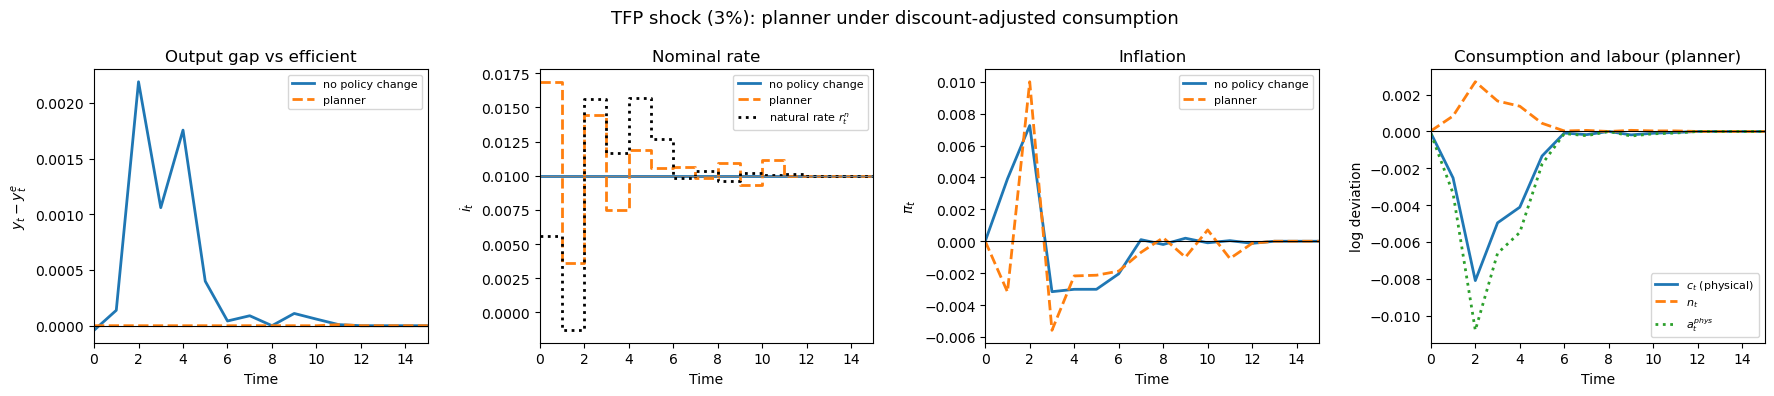

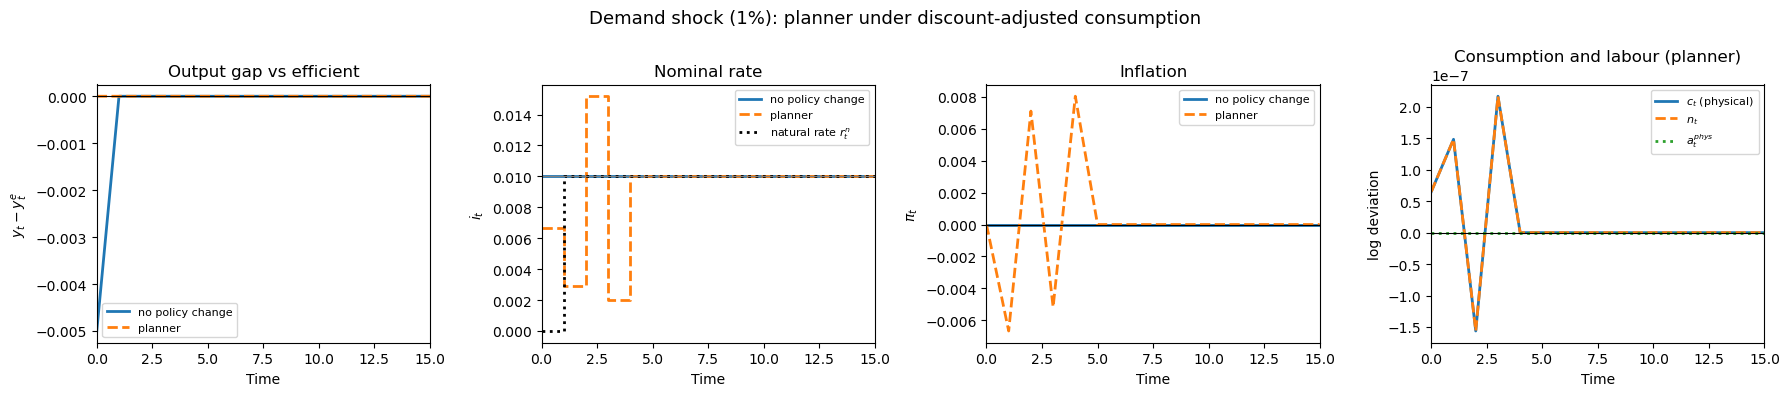

In [10]:
def irf_figure(name, fname, horizon=16):
    r_opt, s_opt, s_base = summary[name]
    t = np.arange(horizon)
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.0))

    for ax, key, ttl, ylab in [
            (axes[0], None, 'Output gap vs efficient', '$y_t - y^e_t$'),
            (axes[1], 'i', 'Nominal rate', '$i_t$'),
            (axes[2], 'pi', 'Inflation', '$\\pi_t$'),
            (axes[3], None, 'Consumption and labour (planner)', 'log deviation')]:
        ax.set_xlabel('Time'); ax.set_ylabel(ylab); ax.set_title(ttl)
        ax.set_xlim(0, horizon - 1)

    axes[0].plot(t, (s_base['y_phys'] - s_base['y_eff'])[:horizon], lw=2,
                 label='no policy change')
    axes[0].plot(t, (s_opt['y_phys'] - s_opt['y_eff'])[:horizon], '--', lw=2,
                 label='planner')
    axes[0].axhline(0, color='k', lw=0.8); axes[0].legend(fontsize=8)

    axes[1].step(t, s_base['i'][:horizon], where='post', lw=2, label='no policy change')
    axes[1].step(t, s_opt['i'][:horizon], where='post', ls='--', lw=2, label='planner')
    axes[1].step(t, s_base['r_nat'][:horizon], where='post', ls=':', lw=2, color='k',
                 label='natural rate $r^n_t$')
    axes[1].axhline(rho, color='grey', lw=0.8); axes[1].legend(fontsize=8)

    axes[2].plot(t, s_base['pi'][:horizon], lw=2, label='no policy change')
    axes[2].plot(t, s_opt['pi'][:horizon], '--', lw=2, label='planner')
    axes[2].axhline(0, color='k', lw=0.8); axes[2].legend(fontsize=8)

    axes[3].plot(t, s_opt['y_phys'][:horizon], lw=2, label='$c_t$ (physical)')
    axes[3].plot(t, (s_opt['y_phys'] - s_opt['a_phys'])[:horizon], '--', lw=2,
                 label='$n_t$')
    axes[3].plot(t, s_opt['a_phys'][:horizon], ':', lw=2, label='$a^{phys}_t$')
    axes[3].axhline(0, color='k', lw=0.8); axes[3].legend(fontsize=8)

    fig.suptitle(f'{name}: planner under discount-adjusted consumption', fontsize=13)
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()


irf_figure('TFP shock (3%)', '../semi_endo_planner_adj_A.png')
irf_figure('Demand shock (1%)', '../semi_endo_planner_adj_demand.png')

## 6. The TFP-shock rate path oscillates, and it is real

The optimal sequence under the TFP shock alternates high–low rather than decaying
monotonically. Before reading anything into that it has to be separated from optimiser
noise on a flat landscape: below, the path is re-solved at several horizons and from
several starting points.

In [11]:
hist_A, LA = results['TFP shock (3%)']
print('TFP shock: optimal path across horizons (best of 3 starting points each)\n')
print(f'{"L":>3} {"objective":>20}   first 8 periods')
print('-' * 80)
for L in [10, 12, 14, 16]:
    if L in hist_A:
        r_, f_, _ = hist_A[L]
        print(f'{L:>3} {f_:>20.12f}   {np.round(r_[:8], 5)}')

print('\nsame L, different starting points:')
def obj_A(r):
    return -welfare(solve(r, **CASES['TFP shock (3%)']))[0]
for label, seed in [('flat at rho', np.ones(12) * rho),
                    ('ramp', np.linspace(0.005, 0.015, 12)),
                    ('flat at 0.005', np.full(12, 0.005)),
                    ('flat at 0.02', np.full(12, 0.02))]:
    res = minimize(obj_A, seed, method='L-BFGS-B', bounds=[(0.0, 0.05)] * 12,
                   options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
    print(f'   {label:<15} obj={res.fun:.12f}   {np.round(res.x[:6], 5)}')

r_A = hist_A[LA][0]
print(f'\nsign of successive changes in i_t: '
      f'{np.sign(np.diff(r_A[:8])).astype(int)}')
print('alternating +/- => genuine oscillation, not a monotone decay')

print('\nfor contrast, the demand-shock optimum is NOT unique:')
hist_D, LD = results['Demand shock (1%)']
for L in [4, 6, 8, 10]:
    if L in hist_D:
        r_, f_, _ = hist_D[L]
        print(f'   L={L:>2}  obj={f_:.12f}   i[:4]={np.round(r_[:4], 5)}')
print('   -> identical objective, different paths: a flat set of optima.')

TFP shock: optimal path across horizons (best of 3 starting points each)

  L            objective   first 8 periods
--------------------------------------------------------------------------------
 10      34.782614615235   [0.01594 0.00441 0.01329 0.00858 0.01057 0.01195 0.00909 0.01153]
 12      34.782614608797   [0.01625 0.00413 0.01367 0.0082  0.01102 0.01148 0.00963 0.01095]
 14      34.782614608797   [0.01639 0.00401 0.01384 0.00805 0.0112  0.01129 0.00985 0.01071]
 16      34.782614608798   [0.01645 0.00396 0.01391 0.00797 0.01129 0.0112  0.00995 0.01059]

same L, different starting points:


   flat at rho     obj=34.782614608798   [0.01626 0.00412 0.01368 0.00819 0.01103 0.01148]


   ramp            obj=34.782614608797   [0.01625 0.00413 0.01367 0.0082  0.01102 0.01148]


   flat at 0.005   obj=34.782614608799   [0.01626 0.00413 0.01368 0.0082  0.01102 0.01148]


   flat at 0.02    obj=34.782614608797   [0.01626 0.00412 0.01368 0.0082  0.01102 0.01148]

sign of successive changes in i_t: [-1  1 -1  1 -1  1 -1]
alternating +/- => genuine oscillation, not a monotone decay

for contrast, the demand-shock optimum is NOT unique:
   L= 4  obj=34.754380404667   i[:4]=[0.00666 0.00288 0.01518 0.00197]
   L= 6  obj=34.754380404667   i[:4]=[0.00388 0.00535 0.01195 0.00501]
   L= 8  obj=34.754380404667   i[:4]=[0.00238 0.0067  0.0102  0.00666]
   L=10  obj=34.754380404668   i[:4]=[0.00158 0.00741 0.00928 0.00753]
   -> identical objective, different paths: a flat set of optima.


The oscillation is stable across $L=10\ldots16$ and across four starting points, and the
objective is identical to twelve digits, so it is a property of the problem rather than of
the solver. It is what the staggered structure implies: firms reprice in cohorts indexed by
$\tau_i$, and the rate that is right for the cohort repricing at $t$ is wrong for the one
repricing at $t+1$, so the planner alternates.

The demand shock behaves oppositely — many different paths hit the same optimum, because
physical productivity is flat and the planner only has to deliver one intertemporal
consumption profile.

## 7. Does time-to-build matter for the planner?

Re-solve with $\tau_i$ forced to zero, so firms reprice immediately and $d_t \equiv 0$.

In [12]:
print(f'{"case":<20}{"time to build":>15}{"U base":>17}{"U planner":>17}'
      f'{"peak|y-y_eff| opt":>20}')
print('-' * 89)
ttb_rows = {}
for name, kw in CASES.items():
    for ttb in [False, True]:
        kw2 = dict(kw, time_to_build=ttb)
        def obj(r, kw2=kw2):
            return -welfare(solve(r, **kw2))[0]
        best = None
        for seed in SEEDS:
            res = minimize(obj, seed(8), method='L-BFGS-B', bounds=[(0.0, 0.05)] * 8,
                           options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
            if best is None or res.fun < best.fun:
                best = res
        s_o = solve(best.x, **kw2)
        s_b = solve(np.ones(3) * rho, **kw2)
        ttb_rows[(name, ttb)] = (best.x, s_o, s_b)
        print(f'{name:<20}{str(ttb):>15}{welfare(s_b)[0]:>17.9f}{welfare(s_o)[0]:>17.9f}'
              f'{np.max(np.abs(s_o["y_phys"] - s_o["y_eff"])):>20.3e}')

print('\nrequired rate paths (first 4 periods):')
for (name, ttb), (r_, _, _) in ttb_rows.items():
    print(f'   {name:<20} ttb={str(ttb):<6} {np.round(r_[:4], 5)}')
print('\n-> attainable welfare is essentially identical with and without time to build.')
print('   What time to build changes is the PATH policy must follow to get there.')
print('   Without it the demand-shock answer is the textbook one, i_t = r^n_t.')

case                  time to build           U base        U planner   peak|y-y_eff| opt
-----------------------------------------------------------------------------------------


TFP shock (3%)                False    -34.782633515    -34.782614625           8.313e-05


TFP shock (3%)                 True    -34.782632633    -34.782614637           1.098e-04


Demand shock (1%)             False    -34.754430239    -34.754380405           1.548e-07


Demand shock (1%)              True    -34.754430239    -34.754380405           1.162e-07

required rate paths (first 4 periods):
   TFP shock (3%)       ttb=False  [0.00867 0.00628 0.01359 0.00866]
   TFP shock (3%)       ttb=True   [0.01555 0.00475 0.01282 0.00904]
   Demand shock (1%)    ttb=False  [0.   0.01 0.01 0.01]
   Demand shock (1%)    ttb=True   [0.00238 0.0067  0.0102  0.00666]

-> attainable welfare is essentially identical with and without time to build.
   What time to build changes is the PATH policy must follow to get there.
   Without it the demand-shock answer is the textbook one, i_t = r^n_t.


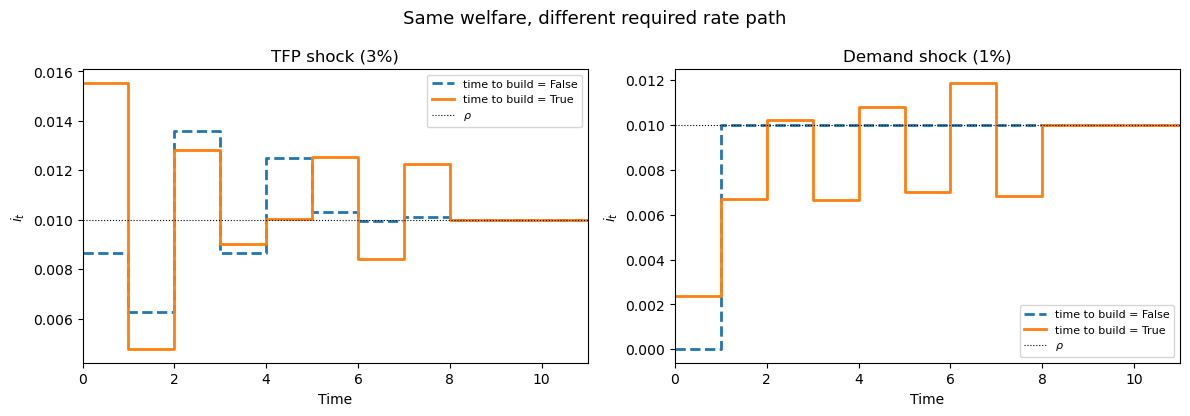

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
H = 12
t = np.arange(H)
for ax, name in zip(axes, CASES):
    for ttb, ls in [(False, '--'), (True, '-')]:
        r_, s_o, _ = ttb_rows[(name, ttb)]
        ax.step(t, s_o['i'][:H], where='post', ls=ls, lw=2,
                label=f'time to build = {ttb}')
    ax.axhline(rho, color='k', lw=0.8, ls=':', label=r'$\rho$')
    ax.set_xlabel('Time'); ax.set_ylabel('$i_t$'); ax.set_title(name)
    ax.legend(fontsize=8); ax.set_xlim(0, H - 1)
fig.suptitle('Same welfare, different required rate path', fontsize=13)
plt.tight_layout()
plt.savefig('../semi_endo_planner_adj_ttb.png', dpi=150, bbox_inches='tight')
plt.show()

## Summary

Taking the discount-adjusted welfare criterion as given, the planner's problem is
well-posed for both shocks — and the two shocks behave quite differently.

1. **Both are interior.** Adjusted utility peaks exactly at $i=\rho$ and falls away on both
   sides for the TFP and the demand shock alike. The unadjusted criterion is monotone in
   $i$ for both, which is what drove the original notebook to the bound.

2. **Both attain the first best, but at different cost in policy freedom.** The demand
   shock needs $L=4$ free periods; the TFP shock needs $L=11$ for the objective and $L=12$
   before the gap itself closes to $\sim\!3\times10^{-7}$. The staggering matrix takes 15
   periods to work through, and policy needs a comparable horizon before it can neutralise
   the whole path — with only three free periods the residual gap is $1.8\times10^{-3}$,
   roughly the size of the shock's own effect on potential, and it is still $10^{-4}$ at
   $L=10$.

3. **The TFP-shock optimum oscillates; the demand-shock optimum is a flat set.** The
   alternating rate path under the TFP shock is stable across $L=10\ldots16$ and four
   starting points with the objective identical to twelve digits, so it is structural: firms
   reprice in cohorts indexed by $\tau_i$, and the rate suited to the cohort repricing at
   $t$ is wrong for the one repricing at $t+1$. Under the demand shock, by contrast, many
   distinct paths achieve the identical optimum, so no single "optimal path" should be
   quoted without saying it is one of many.

4. **Time to build does not change attainable welfare — only the path.** With $\tau$ forced
   to zero the planner reaches the same utility for both shocks; what changes is the
   sequence needed. Without time to build the demand-shock answer collapses to the textbook
   $i_t = r^n_t$; with it, policy has to work around the staggered price adjustment.

One caveat carried over from `demand_planner_interior.ipynb`: the adjustment divides out
the whole discount factor, and a small part of it — $0.057\%$ of $2.88\%$ at $i=\rho$ — is
genuinely physical, being the relative-price dispersion across firms with different
$\tau_i$. Removing it also removes the Friedman-rule motive. That is the right call if the
long-run level of the nominal rate is not the question being asked; if it is, the
two-aggregate treatment in section 7 of that notebook is the one to use.